# IRWA Final Project — Part 1: Text Processing and Exploratory Data Analysis

This notebook (1) pre-processes the fashion-products corpus and (2) explores it.
All the pre-processing logic lives in `myapp/core/preprocessing.py` so that Parts 2–4
(indexing, ranking, web app) reuse **exactly the same** pipeline for documents and queries.

**Run from the repository root or from this folder.** Required files:
`data/fashion_products_dataset.json` and `data/validation_labels.csv`.

In [1]:
import sys, math, re, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

# Locate the repository root (the folder that contains `myapp/`) so the notebook works
# whether it is launched from the repo root or from project_progress/part_1.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "myapp").is_dir())
sys.path.insert(0, str(ROOT))

for resource in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=True)

from myapp.core.preprocessing import (
    load_raw_corpus, preprocess_corpus, preprocess_text, normalise_text, tokenize,
    remove_stopwords, flatten_product_details, product_details_to_text, OUTPUT_FIELDS,
)

DATA = ROOT / "data"
FIG = ROOT / "project_progress" / "part_1" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore")

def savefig(name):
    """Save the current figure into project_progress/part_1/figures for the report."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Loading the data

In [2]:
raw = load_raw_corpus(DATA / "fashion_products_dataset.json")
print(f"{len(raw):,} products, {raw.shape[1]} fields, {raw.pid.nunique():,} unique pids")
raw.head(3)

28,080 products, 17 fields, 28,080 unique pids


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,69% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-10...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,66% off,[https://rukminim1.flixcart.com/image/128/128/kfyasnk0/track-pant/g/5/y/s-19...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets':...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,68% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/e/c/s/xl-1...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...


No field is `null`, but many are **empty strings**, which `isna()` does not catch.
Counting empty strings gives the real picture of missing data:

In [3]:
def is_empty(v):
    """True for '', whitespace, empty list/dict or None."""
    if v is None: return True
    if isinstance(v, (list, dict)): return len(v) == 0
    return str(v).strip() == ""

missing = pd.DataFrame({
    "empty": {c: raw[c].map(is_empty).sum() for c in OUTPUT_FIELDS},
})
missing["empty_%"] = (100 * missing["empty"] / len(raw)).round(1)
missing.sort_values("empty", ascending=False)

,empty,empty_%
description,11150,39.7
average_rating,2261,8.1
brand,2009,7.2
seller,1643,5.9
discount,855,3.0
actual_price,777,2.8
selling_price,2,0.0
pid,0,0.0
title,0,0.0
category,0,0.0


- Always available: Title, category, subcategory, product details, and URL.
- Missing descriptions (39.7%): Titles and product details must be detailed enough to stand on their own.
- Other gaps: 8.1% of products have no rating, and 2.8% lack a list price.

## 2. Pre-processing

Pipeline applied to `title`, `description`, the values of `product_details` and `brand`
(see the docstrings in `preprocessing.py`):

1. Unicode → ASCII folding and lower-casing
2. Domain normalisation: `t-shirt / t shirt / tee → tshirt`, `sweat shirt → sweatshirt`, glued compounds such as `slimfit → slim fit`
3. Punctuation removal (replaced by spaces, which also splits words glued by punctuation like `look.Designed`)
4. Tokenization (`nltk.word_tokenize`)
5. Stop-word removal (NLTK English list), plus single characters and pure numbers
6. Porter stemming

The same `preprocess_text` function is used for queries:

In [4]:
examples = [
    "women full sleeve sweatshirt cotton",
    "men slim jeans blue",
    "Men's Printed T-Shirt (Pack of 2)",
    raw.description.iloc[0],
]
for text in examples:
    print(f"{text[:90]!r}\n  -> {preprocess_text(text)}\n")

'women full sleeve sweatshirt cotton'
  -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']

'men slim jeans blue'
  -> ['men', 'slim', 'jean', 'blue']

"Men's Printed T-Shirt (Pack of 2)"
  -> ['men', 'print', 'tshirt', 'pack']

'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Com'
  -> ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']



- Consistent Normalization: Queries and documents use the same pipeline, so terms match directly.
- Internal Stemming: Stems like "sleev" aren't standard words, but this is expected as they are only used internally by the index.
- Preserved Context: Key modifiers, such as gender ("men", "women"), fit ("full", "slim"), and colors, are kept rather than treated as stop words.

In [5]:
%%time
corpus = preprocess_corpus(raw)
corpus[["pid", "title", "title_tokens", "details_tokens", "brand_kw", "selling_price_num", "discount_num", "average_rating_num"]].head()

CPU times: user 3.43 s, sys: 28.7 ms, total: 3.46 s
Wall time: 3.49 s


,pid,title,title_tokens,details_tokens,brand_kw,selling_price_num,discount_num,average_rating_num
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, multicolor]",york,921.0,69.0,3.9
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","[drawstr, elast, side, pocket, cotton, blend, solid, blue]",york,499.0,66.0,3.9
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, multicolor]",york,931.0,68.0,3.9
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, multicolor]",york,911.0,69.0,3.9
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]","[drawstr, elast, side, pocket, cotton, blend, solid, brown, grey]",york,943.0,68.0,3.9


### Effect of every step on the vocabulary

In [6]:
def vocab_stats(texts):
    """Return token count and vocabulary size after each pipeline step."""
    steps = {"raw split": Counter(), "normalised+tokenized": Counter(),
             "stop words removed": Counter(), "stemmed": Counter()}
    for t in texts:
        steps["raw split"].update(str(t).split())
        toks = tokenize(normalise_text(t))
        steps["normalised+tokenized"].update(toks)
        toks = remove_stopwords(toks)
        steps["stop words removed"].update(toks)
        steps["stemmed"].update(preprocess_text(t))
    return pd.DataFrame({k: {"tokens": sum(c.values()), "vocabulary": len(c)} for k, c in steps.items()}).T

all_text = raw.title + " " + raw.description
vs = vocab_stats(all_text)
vs["vocab_reduction_%"] = (100 * (1 - vs.vocabulary / vs.vocabulary.iloc[0])).round(1)
vs

,tokens,vocabulary,vocab_reduction_%
raw split,1017425,13521,0.0
normalised+tokenized,1023834,6545,51.6
stop words removed,690067,6233,53.9
stemmed,690067,4750,64.9


- Normalization: Halves the unique vocabulary from 13.521 to 6.545 terms.
- Stop-Word Removal: Eliminates 33% of overall tokens with almost no impact on unique vocabulary size.
- Stemming: Further reduces terms to 4.750, achieving a total vocabulary reduction of 65%.

## 3. How to handle `category`, `sub_category`, `brand`, `seller`, `product_details`

To decide whether these fields should be merged into the text or indexed separately, we
measure how **distinctive** they are: number of distinct values, normalised entropy
(0 = every product has the same value, 1 = uniform), and the IDF a value would get if it
were indexed as a term (`log(N/df)`; low IDF = the term barely helps ranking).

In [7]:
N = len(corpus)
def field_profile(series):
    """Cardinality, entropy and IDF stats of a categorical field."""
    s = series[series != ""]
    counts = s.value_counts()
    p = counts / counts.sum()
    entropy = -(p * np.log2(p)).sum()
    idf = np.log(N / counts)
    return {
        "distinct values": len(counts),
        "coverage %": round(100 * len(s) / N, 1),
        "top value share %": round(100 * counts.iloc[0] / len(s), 1),
        "norm. entropy": round(entropy / np.log2(len(counts)), 2) if len(counts) > 1 else 0,
        "median IDF": round(float(np.median(idf)), 2),
        "IDF of top value": round(float(idf.iloc[0]), 2),
    }

profile = pd.DataFrame({f: field_profile(corpus[f + "_kw"]) for f in ["category", "sub_category", "brand", "seller"]}).T
profile

,distinct values,coverage %,top value share %,norm. entropy,median IDF,IDF of top value
category,4.0,100.0,96.6,0.11,4.97,0.03
sub_category,22.0,100.0,54.5,0.51,6.23,0.61
brand,321.0,92.8,3.6,0.82,7.30,3.39
seller,534.0,94.1,5.3,0.79,8.45,2.99


In [8]:
print(corpus.category_kw.value_counts(), "\n")
print(corpus.sub_category_kw.value_counts())

category_kw
clothing and accessories    27118
footwear                      920
bags, wallets & belts          41
toys                            1
Name: count, dtype: int64 

sub_category_kw
topwear                                 15310
bottomwear                               3666
winter wear                              2493
innerwear and swimwear                   1762
clothing accessories                     1742
kurtas, ethnic sets and bottoms          1180
men's footwear                            920
fabrics                                   534
sleepwear                                 122
blazers, waistcoats and suits             103
tracksuits                                 90
raincoats                                  34
sunshopping bags, wallets & belts          31
uber urban clothing and accessories        28
inspire clothing and accessories           27
crocks club clothing and accessories       15
roy clothing and accessories               12
winsome deal bags, wallets

- Category (IDF 0.03): 96.6% of products share the exact same value, making it effectively useless as a search term.
- Sub-category: Features overly broad values ("Topwear") that rarely match queries, plus noisy seller data.
- Brand & Seller: Highly distinctive when searched directly, though brand values are frequently cut off ("Pu", "Lev").

`product_details` is a list of key/value pairs. Which keys exist, and how often?

In [9]:
details_keys = Counter(k for d in corpus.product_details for k in d)
print(f"{len(details_keys)} distinct keys")
keys_df = pd.DataFrame(details_keys.most_common(25), columns=["key", "products"])
keys_df["%"] = (100 * keys_df.products / N).round(1)
keys_df["example values"] = keys_df.key.map(
    lambda k: ", ".join(pd.Series([d[k] for d in corpus.product_details if k in d]).value_counts().index[:4].astype(str)))
keys_df

127 distinct keys


,key,products,%,example values
0,Fabric,25959,92.4,"Cotton Blend, Pure Cotton, Polycotton, Polyester"
1,Style Code,25763,91.7,"3, 8, cotton Printed Shirt Fabric (Unstitched), sdm600"
2,Pattern,25692,91.5,"Solid, Printed, Self Design, Striped"
3,Fabric Care,21830,77.7,"Gentle Machine Wash, Regular Machine Wash, Machine wash as per tag, Hand wash"
4,Suitable For,19139,68.2,"Western Wear, Maternity Wear, Ethnic Wear, Fusion Wear"
5,Sleeve,18861,67.2,"Half Sleeve, Full Sleeve, Short Sleeve, Sleeveless"
6,Pack of,17953,63.9,"1, 2, 3, 4"
7,Type,17394,61.9,"Round Neck, Polo Neck, Shirt Fabric, Straight"
8,Ideal For,16983,60.5,"Women, Men, Women, Girls, Men, Boys"
9,Fit,16808,59.9,"Regular, Slim, Slim Fit, Regular Fit"


- Retained Keys: Core descriptors including Fabric, Pattern, Sleeve, Fit, Ideal For, Color, and Neck Type.
- Dropped Keys: Excludes codes, care instructions, packaging, origin, warranty, and measurement data using DETAIL_KEYS_TO_DROP (case-insensitive).
- Conditional Keys: Other Details is kept unless it contains care instructions.

### Evidence from `validation_labels.csv`

For each validation query we check, for relevant (1) and non-relevant (0) documents, the
share of query terms found in each field. This tells us **where** the matching
information actually lives.

In [10]:
labels = pd.read_csv(DATA / "validation_labels.csv")
queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
labelled = labels.merge(corpus, on="pid", suffixes=("_label", ""))
fields = {"title": "title_tokens", "description": "description_tokens", "details": "details_tokens",
          "brand": "brand_tokens", "sub_category": None, "all text": "all_tokens"}

rows = []
for _, r in labelled.iterrows():
    q = set(preprocess_text(queries[r.query_id]))
    row = {"query_id": r.query_id, "label": r.labels}
    for name, col in fields.items():
        toks = set(preprocess_text(r.sub_category)) if col is None else set(r[col])
        row[name] = len(q & toks) / len(q)
    rows.append(row)
coverage = pd.DataFrame(rows).groupby(["query_id", "label"]).mean().round(2)
coverage

title  description  details  brand  sub_category  all text
query_id label                                                            
1        0       0.46         0.63     0.57    0.0           0.0       1.0
         1       0.80         0.58     0.68    0.0           0.0       1.0
2        0       0.72         0.40     0.48    0.0           0.0       0.8
         1       0.80         0.35     0.65    0.0           0.0       0.9

In [11]:
# Which query terms are missing from the TITLE of relevant documents, and are they found elsewhere?
for qid, q in queries.items():
    qt = preprocess_text(q)
    rel = labelled[(labelled.query_id == qid) & (labelled.labels == 1)]
    print(f"Query {qid}: {q}")
    for term in qt:
        in_title = rel.title_tokens.map(lambda t: term in t).mean()
        in_details = rel.details_tokens.map(lambda t: term in t).mean()
        in_desc = rel.description_tokens.map(lambda t: term in t).mean()
        print(f"  {term:12s} title {in_title:4.0%}  details {in_details:4.0%}  description {in_desc:4.0%}")

Query 1: women full sleeve sweatshirt cotton
  women        title 100%  details  23%  description  46%
  full         title 100%  details 100%  description  46%
  sleev        title 100%  details 100%  description  38%
  sweatshirt   title 100%  details  46%  description  69%
  cotton       title   0%  details  69%  description  92%
Query 2: men slim jeans blue
  men          title  70%  details  70%  description   0%
  slim         title  50%  details  10%  description  50%
  jean         title 100%  details  80%  description  60%
  blue         title 100%  details 100%  description  30%


In [12]:
labelled[["query_id", "labels", "title", "brand", "sub_category"]].assign(
    fabric=labelled.product_details.map(lambda d: d.get("Fabric")),
    ideal_for=labelled.product_details.map(lambda d: d.get("Ideal For")),
).sort_values(["query_id", "labels"]).head(40)

,query_id,labels,title,brand,sub_category,fabric,ideal_for
1,1,0,Full Sleeve Striped Women Sweatshirt,REEB,Winter Wear,Polyester Blend,None
4,1,0,Full Sleeve Solid Women Sweatshirt,Pu,Winter Wear,Cotton Blend,None
6,1,0,Typography Women V Neck Multicolor T-Shirt (Pack of 2),Free Authori,Topwear,Pure Cotton,Women
11,1,0,Typography Women V Neck Multicolor T-Shirt (Pack of 2),Free Authori,Topwear,Pure Cotton,Women
12,1,0,Full Sleeve Printed Women Sweatshirt,Pu,Winter Wear,Cotton Blend,None
13,1,0,Printed Women V Neck Multicolor T-Shirt (Pack of 2),Free Authori,Topwear,Pure Cotton,Women
19,1,0,Superhero Women Round Neck Multicolor T-Shirt (Pack of 2),Free Authori,Topwear,Pure Cotton,Women
0,1,1,Full Sleeve Printed Women Sweatshirt,CupidSto,Winter Wear,Cotton Blend,None
2,1,1,Full Sleeve Printed Women Sweatshirt,Pu,Winter Wear,Cotton Blend,None
3,1,1,Full Sleeve Graphic Print Women Sweatshirt,Free Authori,Winter Wear,Polycotton,None


- AND Queries Fail on Full Text: Full-text aggregation hits near 100% term overlap across both relevant and non-relevant items, preventing effective separation.
- Title Is Strongest, But Incomplete: Titles distinguish relevance best (0.80 vs. 0.46 for Query 1), but miss key attributes like "cotton" (found in 92% of descriptions and 69% of details, but 0% of titles).
- Gender Dispersal (Query 2): Women's jeans drive the bulk of non-relevant hits. Gender constraints exist only in the title and Ideal For fields, completely bypassing brand and sub_category.

### Decision (Point 3)
- Field Weighting Strategy: We select a hybrid approach. Core text attributes (title, description, product_details, and brand) are indexed as individual token fields for boosting, while also merged into all_tokens as a safety net.
- Structured Facet Filters: Broad/noisy metadata (category, sub_category, seller) are kept purely as exact keywords for navigation, avoiding query noise.
- Dual-Mapped Brand: brand serves a dual role, indexed as text for lexical search and as a keyword for exact filtering.

## 4. Numeric fields: `out_of_stock`, `selling_price`, `discount`, `actual_price`, `average_rating`

They are stored as strings (`"2,999"`, `"69% off"`, `""`) and are parsed into typed columns
(`*_num`). They are **not** indexed as text: a token like `"999"` would match random
products, and numbers support range filters and ranking signals that text matching cannot.

In [13]:
num_cols = ["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]
print("Missing after parsing:\n", corpus[num_cols].isna().sum().to_string())
print("\nRows with no list price (actual = selling, discount = 0):", corpus.price_imputed.sum())
print("Products without rating:", (~corpus.has_rating).sum())
corpus[num_cols].describe().round(2)

Missing after parsing:
 selling_price_num        2
actual_price_num         2
discount_num             2
average_rating_num    2261

Rows with no list price (actual = selling, discount = 0): 775
Products without rating: 2261


,selling_price_num,actual_price_num,discount_num,average_rating_num
count,28078.00,28078.00,28078.00,25819.00
mean,705.64,1442.79,48.73,3.63
std,549.68,940.43,18.73,0.66
min,99.00,149.00,0.00,1.00
25%,390.00,849.00,37.00,3.20
50%,545.00,1199.00,52.00,3.80
75%,820.00,1799.00,62.00,4.10
max,7999.00,12999.00,87.00,5.00


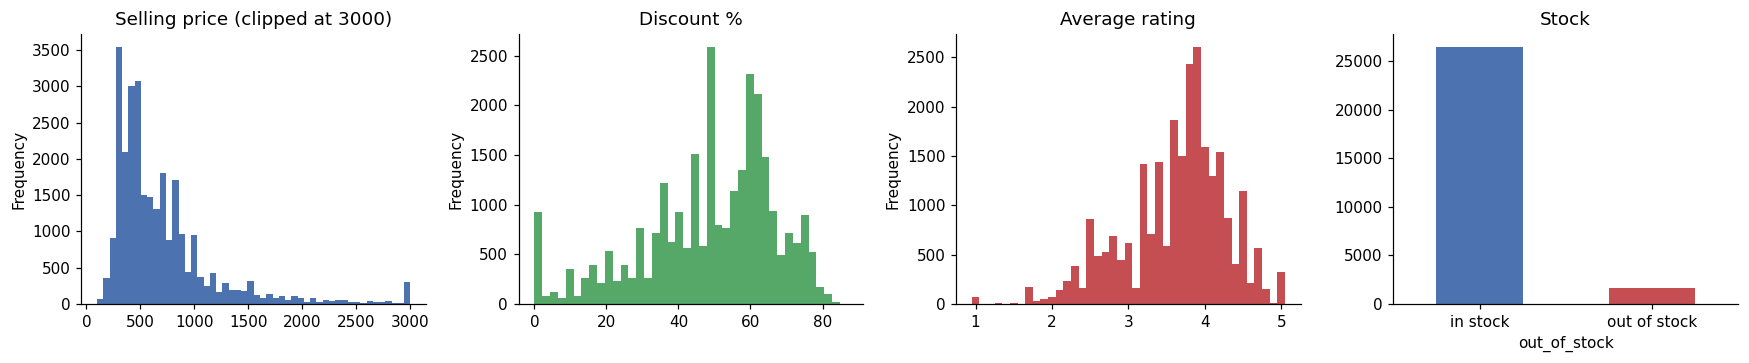

out_of_stock
False    0.941
True     0.059
Name: proportion, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
corpus.selling_price_num.clip(upper=3000).plot.hist(bins=50, ax=axes[0], color="#4C72B0", title="Selling price (clipped at 3000)")
corpus.discount_num.plot.hist(bins=40, ax=axes[1], color="#55A868", title="Discount %")
corpus.average_rating_num.plot.hist(bins=np.arange(0.95, 5.1, 0.1), ax=axes[2], color="#C44E52", title="Average rating")
corpus.out_of_stock.value_counts().rename({False: "in stock", True: "out of stock"}).plot.bar(ax=axes[3], color=["#4C72B0", "#C44E52"], title="Stock", rot=0)
savefig("numeric_distributions")
plt.show()
print(corpus.out_of_stock.value_counts(normalize=True).round(3))

### Decision (Point 4)

- Structured Parsing Over Text Indexing: Numbers are parsed as numeric types to support range queries and prevent random text matches.
- Price & Discount Logic: Missing actual_price values (777 items) are backfilled using selling_price (missing only 2), enabling recomputation of discounts for range filtering and subtle ranking boosts.
- Ratings & Availability Signals: average_rating (2,261 NaNs) acts as a smoothed ranking factor, while out_of_stock drives search demotions or optional filtering.

## 5. Exploratory data analysis

### 5.1 Length of the text fields

In [15]:
lengths = pd.DataFrame({
    "title words": raw.title.str.split().str.len(),
    "description words": raw.description.str.split().str.len(),
    "title terms (processed)": corpus.title_tokens.str.len(),
    "description terms (processed)": corpus.description_tokens.str.len(),
    "details terms (processed)": corpus.details_tokens.str.len(),
})
lengths.describe().round(1)

,title words,description words,title terms (processed),description terms (processed),details terms (processed)
count,28080.0,28080.0,28080.0,28080.0,28080.0
mean,6.5,29.8,6.1,18.5,13.3
std,2.2,44.3,1.8,26.4,6.9
min,1.0,0.0,1.0,0.0,0.0
25%,6.0,0.0,5.0,0.0,10.0
50%,6.0,10.0,6.0,9.0,13.0
75%,7.0,49.0,7.0,28.0,15.0
max,38.0,623.0,27.0,543.0,115.0


- Formulaic Titles: Short and template-driven (median 6 words: pattern + gender + type + color).
- Unbalanced Descriptions: High length variance (median 10 words, max 623), with 40% missing completely.
- Consistent Details: Averages approx. 13 descriptive terms per item.
- Ranking Takeaway: Substantial length disparities across fields make robust length normalization essential for balanced search scoring.

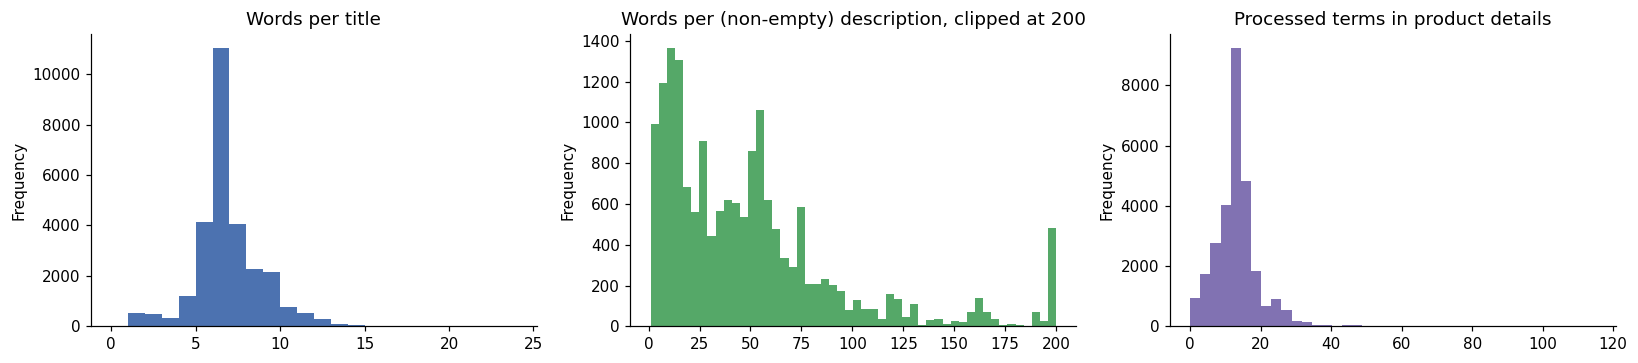

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
lengths["title words"].plot.hist(bins=range(0, 25), ax=axes[0], color="#4C72B0", title="Words per title")
lengths.loc[lengths["description words"] > 0, "description words"].clip(upper=200).plot.hist(
    bins=50, ax=axes[1], color="#55A868", title="Words per (non-empty) description, clipped at 200")
lengths["details terms (processed)"].plot.hist(bins=40, ax=axes[2], color="#8172B2", title="Processed terms in product details")
savefig("length_distributions")
plt.show()

In [17]:
from nltk.tokenize import sent_tokenize
desc = raw.description[raw.description.str.strip() != ""]
# Many descriptions glue sentences without a space ("look.Designed"); add one so the
# sentence splitter can see the boundary.
sentences = desc.str.replace(r"([.!?])(?=[A-Z])", r"\1 ", regex=True).map(sent_tokenize)
sent_len = [len(s.split()) for doc in sentences for s in doc]
print(f"Non-empty descriptions: {len(desc):,} ({100*len(desc)/N:.1f}%)")
print(f"Sentences per description: mean {sentences.str.len().mean():.1f}, median {sentences.str.len().median():.0f}")
print(f"Words per sentence: mean {np.mean(sent_len):.1f}, median {np.median(sent_len):.0f}")

Non-empty descriptions: 16,930 (60.3%)
Sentences per description: mean 3.3, median 2
Words per sentence: mean 15.2, median 14


- Descriptions have a median of 2 sentences of 14 words.
- Many sentences are glued together ("look.Designed"), which is why punctuation is replaced by spaces.

### 5.2 Vocabulary and most frequent terms

In [18]:
term_freq = Counter(t for toks in corpus.all_tokens for t in toks)
doc_freq = Counter(t for toks in corpus.all_tokens for t in set(toks))
print(f"Vocabulary size (processed, all fields): {len(term_freq):,}")
print(f"Terms appearing in a single product (hapax): {sum(1 for c in doc_freq.values() if c == 1):,}")
title_freq = Counter(t for toks in corpus.title_tokens for t in toks)
desc_freq = Counter(t for toks in corpus.description_tokens for t in toks)
pd.DataFrame({"title": [f"{t} ({c})" for t, c in title_freq.most_common(20)],
              "description": [f"{t} ({c})" for t, c in desc_freq.most_common(20)],
              "all fields": [f"{t} ({c})" for t, c in term_freq.most_common(20)]})

Vocabulary size (processed, all fields): 5,710
Terms appearing in a single product (hapax): 1,342


,title,description,all fields
0,women (13146),tshirt (16008),tshirt (36460)
1,men (13060),cotton (10139),cotton (32399)
2,tshirt (12248),wear (9351),neck (29931)
3,neck (11952),comfort (8836),wear (29015)
4,solid (9246),look (6413),women (26987)
5,round (8301),casual (6034),men (26234)
6,print (8123),fit (5835),sleev (25295)
7,pack (4839),made (5643),print (22311)
8,blue (4378),fabric (5516),solid (22281)
9,fit (3923),shirt (5338),round (19876)


- Attribute-Rich Titles: Dominated by key specifications: gender, product type, neck style, pattern, and color (women, men, tshirt, neck, solid).
- Low-IDF Descriptions: High concentration of generic marketing words (wear, comfort, look) that carry little search weight.
- Vocabulary Size: 5.710 total terms, with 23% occurring in only a single product.

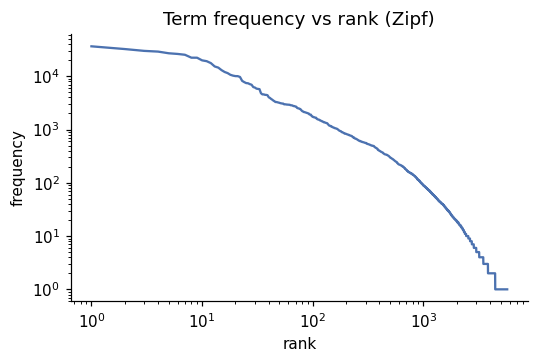

In [19]:
# Zipf's law check: rank vs frequency on log-log axes
freqs = np.array(sorted(term_freq.values(), reverse=True))
plt.figure(figsize=(5, 3.4))
plt.loglog(np.arange(1, len(freqs) + 1), freqs, color="#4C72B0")
plt.xlabel("rank"); plt.ylabel("frequency"); plt.title("Term frequency vs rank (Zipf)")
savefig("zipf")
plt.show()

Heaps: K = 106.8, beta = 0.29
Zipf slope (top 1000 ranks) = -1.14
Vocabulary after the first 10% of products: 3,022 of 5,710


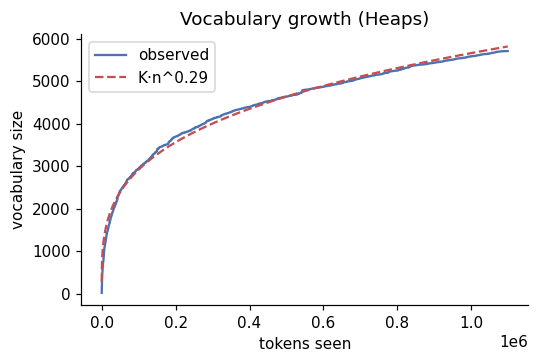

In [20]:
# Heaps' law (vocabulary growth V = K * n^beta) and the slope of the Zipf curve,
# the two text statistics seen in the Indexing & Searching lecture.
seen, n, n_tokens, vocab = set(), 0, [], []
for toks in corpus.all_tokens.sample(frac=1, random_state=0):
    seen.update(toks)
    n += len(toks)
    n_tokens.append(n)
    vocab.append(len(seen))
n_tokens, vocab = np.array(n_tokens), np.array(vocab)
fit = n_tokens > 10_000
beta, log_k = np.polyfit(np.log(n_tokens[fit]), np.log(vocab[fit]), 1)

ranks = np.arange(1, len(freqs) + 1)
zipf_slope = np.polyfit(np.log(ranks[:1000]), np.log(freqs[:1000]), 1)[0]
print(f"Heaps: K = {np.exp(log_k):.1f}, beta = {beta:.2f}")
print(f"Zipf slope (top 1000 ranks) = {zipf_slope:.2f}")
print(f"Vocabulary after the first 10% of products: {vocab[len(vocab) // 10]:,} of {vocab[-1]:,}")

plt.figure(figsize=(5, 3.4))
plt.plot(n_tokens, vocab, color="#4C72B0", label="observed")
plt.plot(n_tokens, np.exp(log_k) * n_tokens ** beta, "--", color="#C44E52", label=f"K·n^{beta:.2f}")
plt.xlabel("tokens seen"); plt.ylabel("vocabulary size"); plt.title("Vocabulary growth (Heaps)")
plt.legend()
savefig("heaps")
plt.show()

- Zipf's Law (Slope ≈−1.1): Matches expected power-law behavior closely (ideal −1.0).
- Heaps' Law (β≈0.29): Considerably lower than standard text (0.4 – 0.6), indicating a highly repetitive e-commerce vocabulary.
- Index Consequence: Keeps overall vocabulary compact while inflating postings lists for domain-dominant terms like tshirt and men.

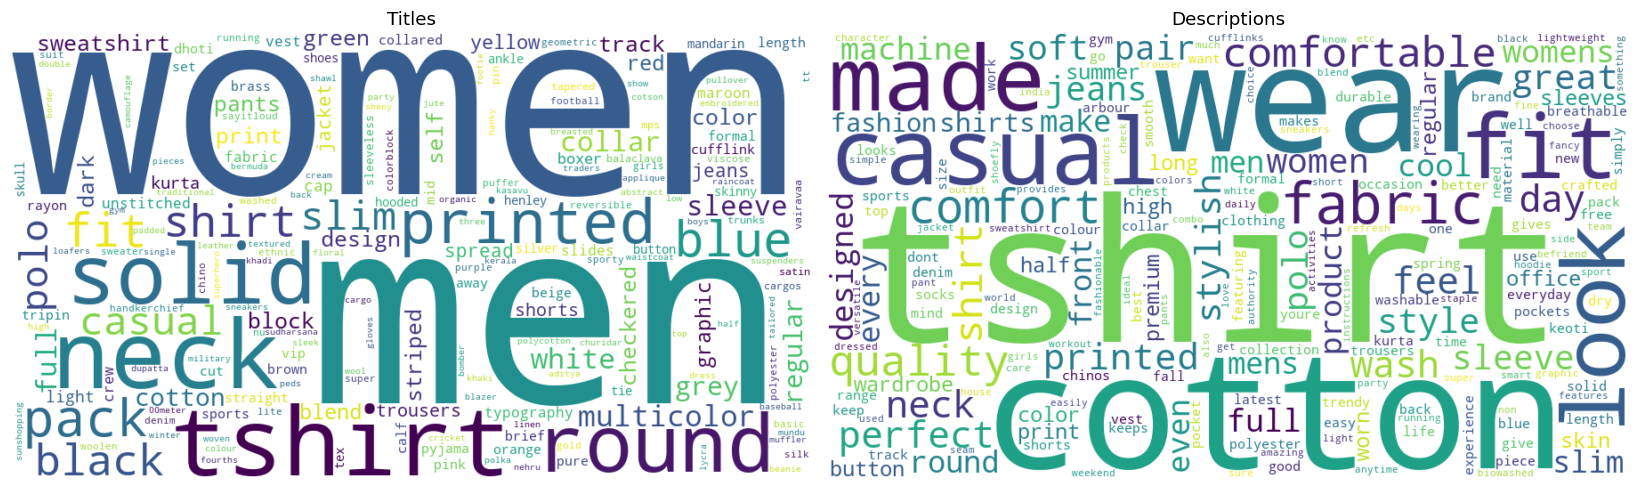

In [21]:
# Word clouds use the UN-stemmed tokens so that the words are readable.
try:
    from wordcloud import WordCloud
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, col, name in [(axes[0], "title", "Titles"), (axes[1], "description", "Descriptions")]:
        freq = Counter(t for text in raw[col] for t in preprocess_text(text, use_stemming=False))
        ax.imshow(WordCloud(width=900, height=500, background_color="white", colormap="viridis")
                  .generate_from_frequencies(freq), interpolation="bilinear")
        ax.set_title(name); ax.axis("off")
    savefig("wordclouds")
    plt.show()
except ImportError:
    print("Install `wordcloud` (pip install wordcloud) to draw the word clouds.")

- Titles say who and what (women, men, tshirt). Descriptions say how it feels (cotton, comfortable).
- The two fields complement each other, so we keep them separate.

### 5.3 Categories, brands and sellers

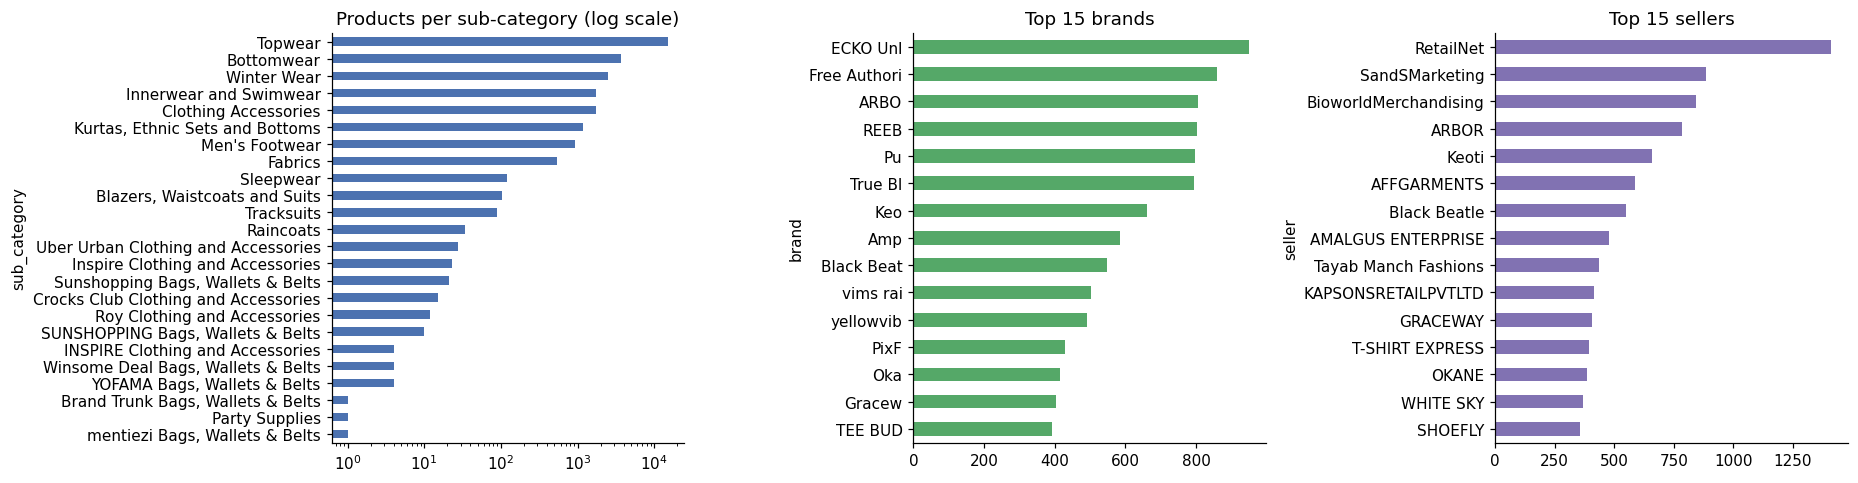

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
corpus.sub_category.value_counts().sort_values().plot.barh(ax=axes[0], color="#4C72B0", logx=True, title="Products per sub-category (log scale)")
corpus.loc[corpus.brand_kw != "", "brand"].value_counts().head(15).sort_values().plot.barh(ax=axes[1], color="#55A868", title="Top 15 brands")
corpus.loc[corpus.seller_kw != "", "seller"].value_counts().head(15).sort_values().plot.barh(ax=axes[2], color="#8172B2", title="Top 15 sellers")
savefig("categories_brands_sellers")
plt.show()

- Sub-Category Long Tail: topwear dominates with over 10000 items, while the distribution drops off sharply into a long tail where 9 sub-categories contain fewer than 100 items.
- Both fields are evenly spread, however, there is a significant drop from the first seller to the seond one.

In [23]:
# Brand names are often truncated in the crawl ("Lev", "ECKO Unl", "Free Authori"):
brands = corpus.loc[corpus.brand_kw != "", "brand"]
print(f"{brands.nunique():,} distinct brands; {(brands.str.len() <= 4).mean():.1%} of products have a brand of <= 4 characters")
print(brands.value_counts().head(25).index.tolist())

324 distinct brands; 34.7% of products have a brand of <= 4 characters
['ECKO Unl', 'Free Authori', 'ARBO', 'REEB', 'Pu', 'True Bl', 'Keo', 'Amp', 'Black Beat', 'vims rai', 'yellowvib', 'PixF', 'Oka', 'Gracew', 'TEE BUD', 'Shoef', 'Marca Disa', 'V', 'CupidSto', 'Urban D', 'Xi', 'AXMA', 'Dudli', 'TOM BU', 'FLEXIM']


- Around a third of products have brand values of 4 characters or fewer due to crawler cutoff (e.g., "Pu" for Puma, "REEB" for Reebok, "Lev" for Levi's).
- A direct query for "puma" or "reebok" will not match these incomplete tokens, making brand far more dependable as a facet filter than a standalone text match..

In [24]:
# Out-of-stock rate per sub-category and per top brand
stock = corpus.groupby("sub_category").agg(products=("pid", "size"), out_of_stock_rate=("out_of_stock", "mean"))
stock.sort_values("out_of_stock_rate", ascending=False).round(3)

,products,out_of_stock_rate
sub_category,,
Clothing Accessories,1742,0.169
Tracksuits,90,0.144
Winter Wear,2493,0.095
Sleepwear,122,0.090
Bottomwear,3666,0.075
"Blazers, Waistcoats and Suits",103,0.058
Innerwear and Swimwear,1762,0.053
Topwear,15310,0.044
Inspire Clothing and Accessories,23,0.043


- While only 5.9% of the overall catalog is out of stock, stock-outs rise significantly in seasonal and peripheral sub-categories like clothing accessories (16.9%) and winter wear (9.5%).
- Out-of-stock products should be penalized or demoted in ranking rather than filtered out completely, preserving search recall while prioritizing purchasable items.

In [25]:
# Price, discount and rating by sub-category
corpus.groupby("sub_category")[["selling_price_num", "discount_num", "average_rating_num"]].median().round(2).sort_values("selling_price_num", ascending=False)

,selling_price_num,discount_num,average_rating_num
sub_category,,,
"Blazers, Waistcoats and Suits",1799.0,60.0,3.40
Tracksuits,1572.5,25.0,3.70
Uber Urban Clothing and Accessories,1449.0,30.0,3.30
Crocks Club Clothing and Accessories,999.0,60.0,3.70
Winter Wear,949.0,50.0,3.80
Inspire Clothing and Accessories,899.0,61.0,3.60
Bottomwear,849.0,48.0,3.70
Raincoats,797.0,55.0,3.60
"mentiezi Bags, Wallets & Belts",749.0,42.0,2.50


- Baseline selling prices vary sharply by product type, ranging from a median of 499 for everyday topwear up to 1,799 for formal blazers, waistcoats and suits.
- Mean ratings remain uniform across categories, clustered narrowly between 3.7 and 3.8 stars, offering minimal discriminative power without bayesian smoothing or review-volume weighting

### 5.4 Product rankings by rating, price and discount

The dataset has no number of reviews, so a 5.0 rating may come from a single review. We
show the raw ranking and, as a more robust alternative, brands ranked by mean rating among
brands with at least 50 rated products.

In [26]:
show = ["pid", "title", "brand", "selling_price_num", "discount_num", "average_rating_num"]
print("Top rated products"); display(corpus.sort_values(["average_rating_num", "discount_num"], ascending=False)[show].head(10))
print("Most expensive"); display(corpus.sort_values("selling_price_num", ascending=False)[show].head(10))
print("Highest discount"); display(corpus.sort_values("discount_num", ascending=False)[show].head(10))

Top rated products


,pid,title,brand,selling_price_num,discount_num,average_rating_num
22441,KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,449.0,82.0,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,249.0,78.0,5.0
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,275.0,77.0,5.0
18497,TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,PixF,289.0,77.0,5.0
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,288.0,77.0,5.0
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,288.0,77.0,5.0
18714,TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,PixF,288.0,77.0,5.0
18738,TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18757,TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,PixF,288.0,77.0,5.0
18781,TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,PixF,288.0,77.0,5.0


Most expensive


,pid,title,brand,selling_price_num,discount_num,average_rating_num
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,20.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sleeve Blazer (Grey),True Bl,7998.0,0.0,2.6
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,40.0,4.5
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,40.0,3.7
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,40.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full Sleeve Blazer (Blue),True Bl,6998.0,0.0,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,6925.0,36.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,39.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,50.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,35.0,NaN


Highest discount


,pid,title,brand,selling_price_num,discount_num,average_rating_num
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,86.0,4.1
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,86.0,4.7
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvib,449.0,85.0,3.2
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,228.0,84.0,4.3
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,280.0,84.0,3.4
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,499.0,84.0,2.7
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,282.0,84.0,4.2
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,230.0,84.0,4.6
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",Fairdea,201.0,84.0,3.8


- Many 5.0-rated items are low-cost T-shirts from single brands; without a review_count attribute to weight credibility, a 5.0 score likely stems from only one review rather than proven popularity.
- The highest price tiers are driven by tailored and outerwear items, specifically blazers, suits, jackets, and tracksuits.
- The highest discount rates occur primarily on budget T-shirts, where artificial list-price markups inflate the perceived discount percentage.

In [27]:
brand_rating = (corpus[corpus.has_rating & (corpus.brand_kw != "")]
                .groupby("brand").agg(products=("pid", "size"), mean_rating=("average_rating_num", "mean"),
                                      median_price=("selling_price_num", "median"))
                .query("products >= 50").sort_values("mean_rating", ascending=False).round(2))
brand_rating.head(10)

,products,mean_rating,median_price
brand,,,
SORA,74,4.61,699.0
PixF,328,4.46,299.0
Cots,277,4.44,325.0
Zack Fo,128,4.33,489.0
Onei,57,4.23,479.0
Gracew,404,4.23,429.0
Marca Disa,334,4.19,539.0
REEBOK CLASSI,75,4.14,1499.0
Byford by Pantaloo,177,4.11,719.0


- Aggregating ratings across brands with at least 50 rated items provides a much more reliable quality signal, surfacing consistent high performers like SORA (4.61) and PixF (4.46).
- If used as a ranking factor, product ratings must be smoothed toward the global dataset mean (3.63) to prevent unvetted items with single 5.0 ratings from dominating search results.

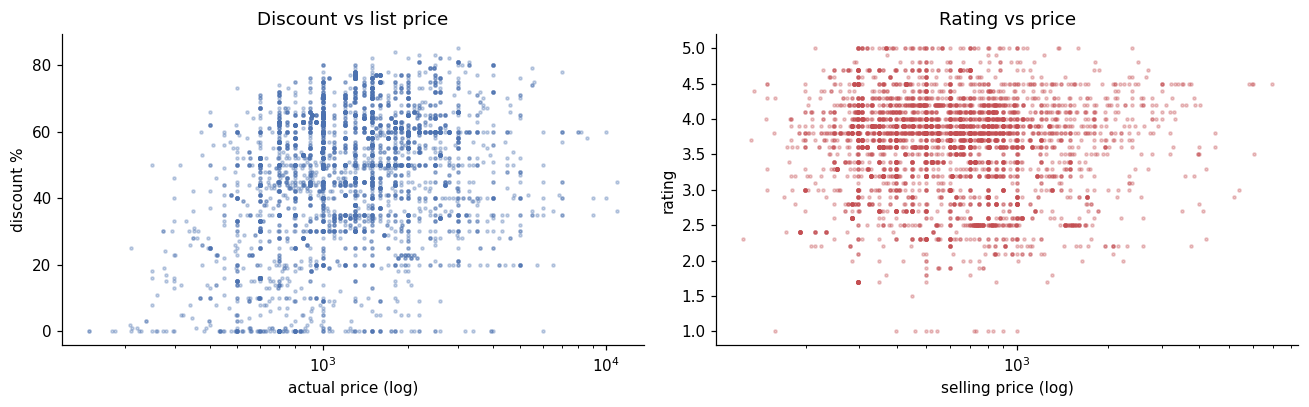

                    selling_price_num  actual_price_num  discount_num  \
selling_price_num                1.00              0.75         -0.37   
actual_price_num                 0.75              1.00          0.28   
discount_num                    -0.37              0.28          1.00   
average_rating_num              -0.03             -0.09         -0.09   

                    average_rating_num  
selling_price_num                -0.03  
actual_price_num                 -0.09  
discount_num                     -0.09  
average_rating_num                1.00  


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sample = corpus.sample(5000, random_state=0)
axes[0].scatter(sample.actual_price_num, sample.discount_num, s=4, alpha=.3, color="#4C72B0")
axes[0].set_xscale("log"); axes[0].set_xlabel("actual price (log)"); axes[0].set_ylabel("discount %"); axes[0].set_title("Discount vs list price")
axes[1].scatter(sample.selling_price_num, sample.average_rating_num, s=4, alpha=.3, color="#C44E52")
axes[1].set_xscale("log"); axes[1].set_xlabel("selling price (log)"); axes[1].set_ylabel("rating"); axes[1].set_title("Rating vs price")
savefig("price_discount_rating")
plt.show()
print(corpus[["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]].corr(method="spearman").round(2))

- Selling price and actual list price exhibit a strong positive correlation (0.75), confirming consistent pricing tiers across the catalog.
- Cheaper products generally carry steeper percentage discounts (correlation of −0.37), reflecting aggressive promotional markdowns on entry-level inventory.
- Average rating shows virtually no correlation with price or discount percentage, confirming that quality/satisfaction signals operate independently of monetary factors and can be tuned as orthogonal ranking features.

### 5.5 Duplicates

Products with the same title are very common (the same garment in several colours or
sizes is listed under different pids). This matters for ranking: many results for a
query can be near-identical.

In [29]:
dup_title = raw.title.duplicated(keep=False).mean()
dup_text = raw.duplicated(subset=["title", "description", "brand"], keep=False).mean()
print(f"Products sharing their title with another product: {dup_title:.1%}")
print(f"Products sharing title + description + brand: {dup_text:.1%}")
raw.title.value_counts().head(10)

Products sharing their title with another product: 87.1%
Products sharing title + description + brand: 56.2%


title
Slides                                      544
Printed Men Round Neck Black T-Shirt        418
Printed Women Round Neck Black T-Shirt      396
Printed Women Round Neck White T-Shirt      349
Rayon Printed Shirt Fabric  (Unstitched)    343
Printed Men Round Neck White T-Shirt        323
Full Sleeve Solid Men Sweatshirt            214
Full Sleeve Solid Women Sweatshirt          204
Printed Women Round Neck Blue T-Shirt       189
Full Sleeve Printed Men Sweatshirt          184
Name: count, dtype: int64

- Approximately 87% of products share their exact title string with at least one other listing, primarily representing identical base models offered in varying colors, sizes, or packs.
- All duplicate variants must remain indexed because ground-truth evaluation relies on individual pid keys, meaning top retrieval rankings will naturally surface clusters of visually identical products.

### 5.6 Entity recognition

Two complementary approaches:

1. **General-purpose NER (spaCy `en_core_web_sm`)** on titles and descriptions — trained on
   news text, so we expect it to struggle with product titles.
2. **Domain entities from `product_details`**: colours, fabrics, fits and target group are
   already given as structured attributes, which is the most reliable "entity" source here.

In [30]:
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
    texts = (raw.title + ". " + raw.description).sample(2000, random_state=0).tolist()
    ents = Counter()
    for doc in nlp.pipe(texts, batch_size=200):
        ents.update((e.label_, e.text.strip()) for e in doc.ents)
    by_label = Counter()
    for (label, _), c in ents.items(): by_label[label] += c
    print("Entity labels:", by_label.most_common(10))
    for label in ["ORG", "GPE", "NORP", "PRODUCT", "PERSON"]:
        print(f"\n{label}:", [t for (l, t), _ in ents.most_common() if l == label][:12])
except (ImportError, OSError):
    print("spaCy model not available: pip install spacy && python -m spacy download en_core_web_sm")

Entity labels: [('ORG', 1897), ('PERSON', 1193), ('CARDINAL', 622), ('PERCENT', 402), ('DATE', 389), ('GPE', 372), ('WORK_OF_ART', 154), ('NORP', 137), ('PRODUCT', 35), ('TIME', 31)]

ORG: ['Printed Women Round Neck White', 'Printed Women Round Neck Black T-Shirt', 'Printed', 'Rayon Printed Shirt Fabric', 'Tripin Brass Cufflink', 'Printed Men Round Neck Black T-Shirt', 'THE AMAZING COMFORT OF A Shoefly POLO T-SHIRTS', 'Printed Men Round Neck White', 'Printed Women Round Neck Blue T-Shirt', 'KEOTI', 'Round Neck Tees', 'Cotton Woven Slim']

GPE: ['Cotton', 'kurta', 'Kurta', 'India', 'INDIA', 'Maroon', 'Ladies', 'Solid', 'Ldhsati', 'Sweatshirt', 'Shoefly', 'Beautiful']

NORP: ['Jeans', 'Indian', 'Joggers', 'Elastic', 'chinese', 'Regular', 'Stylish', 'Combo', 'Suspenders', 'Chinese', 'dhoti', 'French']

PRODUCT: ['T-Shirts', 'S-XXL', 'Round', 'Classic', 'Half Sleeve T-Shirt', 'MicroModal', 'Shirt', 'EverLand', 'Green T-Shirt', 'TE SL CLASSIC TEE', 'Spider', 'Fit']

PERSON: ['Solid Women', 

- Generic news-trained spaCy models perform poorly on catalog text, frequently misclassifying capitalized apparel attributes like "Cotton" as geopolitical locations and fragmented brand/title terms as organizations.
- E-commerce listings consist of headless keyword stacks rather than grammatical sentences, confusing syntax-dependent parsers and reinforcing the need for domain-specific regex and rule-based normalization over standard linguistic taggers.

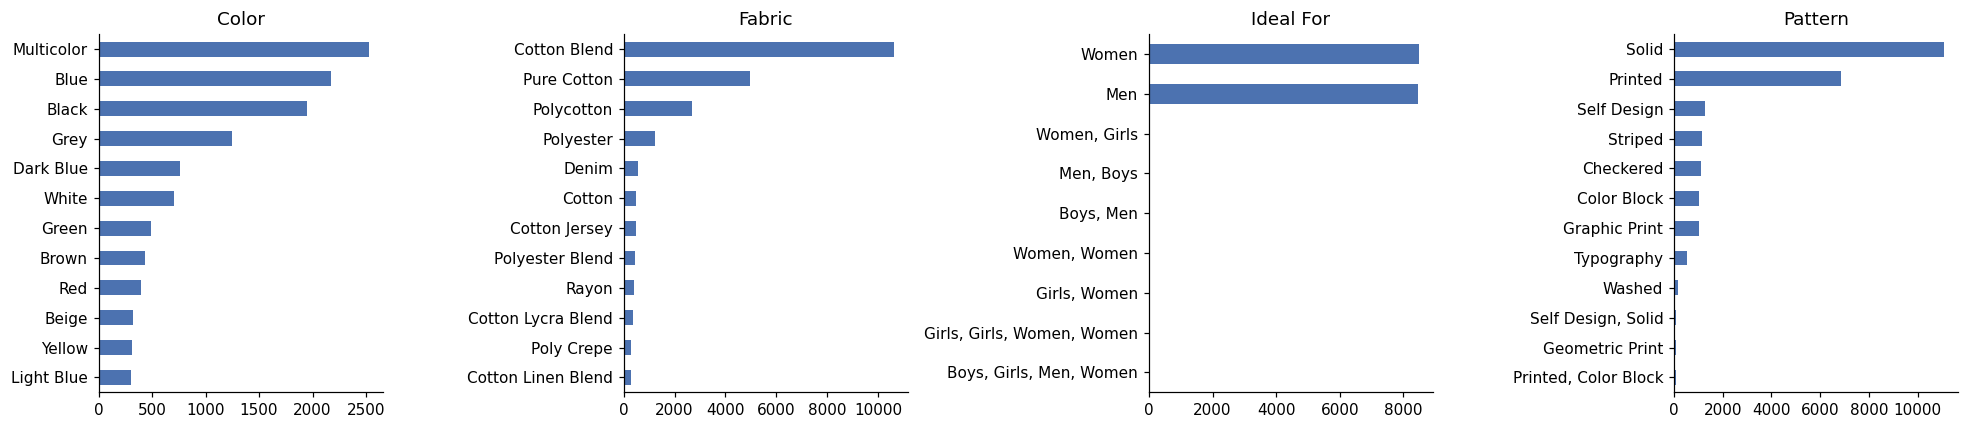

In [31]:
attr = {k: Counter(d[k] for d in corpus.product_details if k in d) for k in ["Color", "Fabric", "Ideal For", "Fit", "Sleeve", "Pattern", "Occasion"]}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, ["Color", "Fabric", "Ideal For", "Pattern"]):
    pd.Series(dict(attr[k].most_common(12))).sort_values().plot.barh(ax=ax, color="#4C72B0", title=k)
savefig("detail_entities")
plt.show()

- Key tabular attributes (Color, Fabric, Ideal For, Pattern, and Sleeve) serve as the true semantic entities of the catalog.
- Because real-world user queries heavily target these concrete features (e.g., fabric types or gender), their values are extracted and indexed directly as searchable text tokens.

## 6. Save the processed corpus

Saved as a pickle (keeps Python lists and dicts) for Part 2 (indexing).

In [33]:
out_path = DATA / "processed_corpus.pkl"
corpus.to_pickle(out_path)
print(f"Saved {len(corpus):,} products with columns:\n{list(corpus.columns)}")

Saved 28,080 products with columns:
['pid', 'title', 'description', 'brand', 'category', 'sub_category', 'product_details', 'seller', 'out_of_stock', 'selling_price', 'discount', 'actual_price', 'average_rating', 'url', 'title_tokens', 'description_tokens', 'details_tokens', 'brand_tokens', 'all_tokens', 'brand_kw', 'seller_kw', 'category_kw', 'sub_category_kw', 'selling_price_num', 'actual_price_num', 'discount_num', 'average_rating_num', 'has_rating', 'price_imputed']


## Summary

| Step | Decision |
|---|---|
| Text | lower-case, normalise, remove punctuation, tokenize, remove stop words and numbers, Porter stem |
| Queries | same pipeline as documents |
| title, description, details, brand | separate token fields + merged `all_tokens` |
| category, sub_category, seller | keywords for filters, not indexed as text |
| Numeric fields | parsed to numbers, used for filtering and ranking |
| Duplicates | kept |